In [13]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import ZGate
from qiskit_aer import AerSimulator

qreg_q = QuantumRegister(3, 'q')
creg_c = ClassicalRegister(3, 'c')
circuit = QuantumCircuit(qreg_q, creg_c)

#superposition
circuit.h(qreg_q[0])
circuit.h(qreg_q[1])
circuit.h(qreg_q[2])

circuit.barrier(qreg_q[0])
circuit.barrier(qreg_q[1])
circuit.barrier(qreg_q[2])

#oracle target state |111>
circuit.append(ZGate().control(1).control(1), [qreg_q[1], qreg_q[2], qreg_q[0]])
circuit.barrier(qreg_q[0])
circuit.barrier(qreg_q[1])
circuit.barrier(qreg_q[2])

#diffuser operator
circuit.h(qreg_q[0])
circuit.h(qreg_q[1])
circuit.h(qreg_q[2])
circuit.x(qreg_q[0])
circuit.x(qreg_q[1])
circuit.x(qreg_q[2])
circuit.append(ZGate().control(1).control(1), [qreg_q[1], qreg_q[2], qreg_q[0]])
circuit.x(qreg_q[0])
circuit.x(qreg_q[1])
circuit.x(qreg_q[2])
circuit.h(qreg_q[2])
circuit.h(qreg_q[1])
circuit.h(qreg_q[0])

circuit.barrier(qreg_q[0])
circuit.barrier(qreg_q[1])
circuit.barrier(qreg_q[2])

#2nd iteration of oracle and diffuser
circuit.append(ZGate().control(1).control(1), [qreg_q[1], qreg_q[2], qreg_q[0]])
circuit.barrier(qreg_q[0])
circuit.barrier(qreg_q[1])
circuit.barrier(qreg_q[2])
circuit.h(qreg_q[0])
circuit.h(qreg_q[1])
circuit.h(qreg_q[2])
circuit.x(qreg_q[0])
circuit.x(qreg_q[1])
circuit.x(qreg_q[2])
circuit.append(ZGate().control(1).control(1), [qreg_q[1], qreg_q[2], qreg_q[0]])
circuit.x(qreg_q[0])
circuit.x(qreg_q[1])
circuit.x(qreg_q[2])
circuit.h(qreg_q[2])
circuit.h(qreg_q[1])
circuit.h(qreg_q[0])
circuit.barrier(qreg_q[0])
circuit.barrier(qreg_q[1])
circuit.barrier(qreg_q[2])

#measurement
circuit.measure(qreg_q[0], creg_c[0])
circuit.measure(qreg_q[1], creg_c[1])
circuit.measure(qreg_q[2], creg_c[2])

#execute the circuit on AerSimulator
simulator = AerSimulator()
job = simulator.run(circuit, shots=1024)
result = job.result()
counts = result.get_counts(circuit)

print("Execution counts:", counts)
print("Target '111' Probability:", counts.get('111', 0) / 1024)

Execution counts: {'111': 966, '110': 10, '010': 9, '101': 11, '100': 10, '011': 8, '001': 5, '000': 5}
Target '111' Probability: 0.943359375


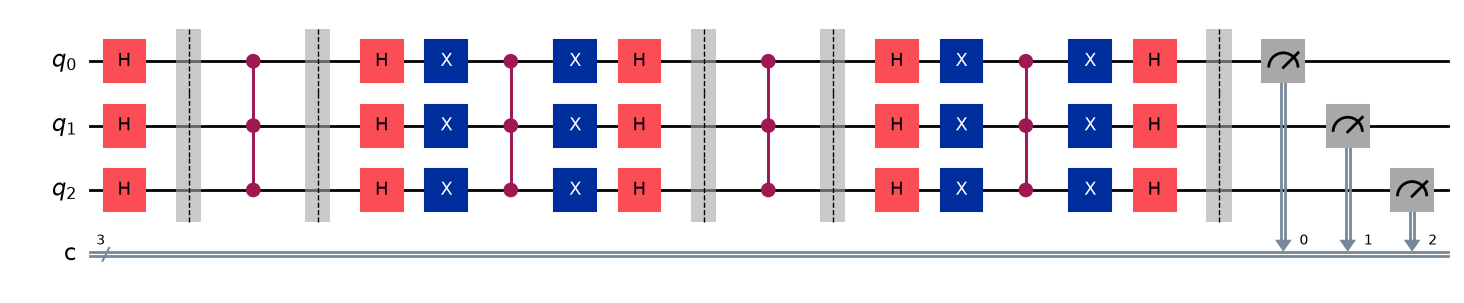

In [14]:
circuit.draw('mpl')

CNOT Count: 24
Circuit Depth: 62


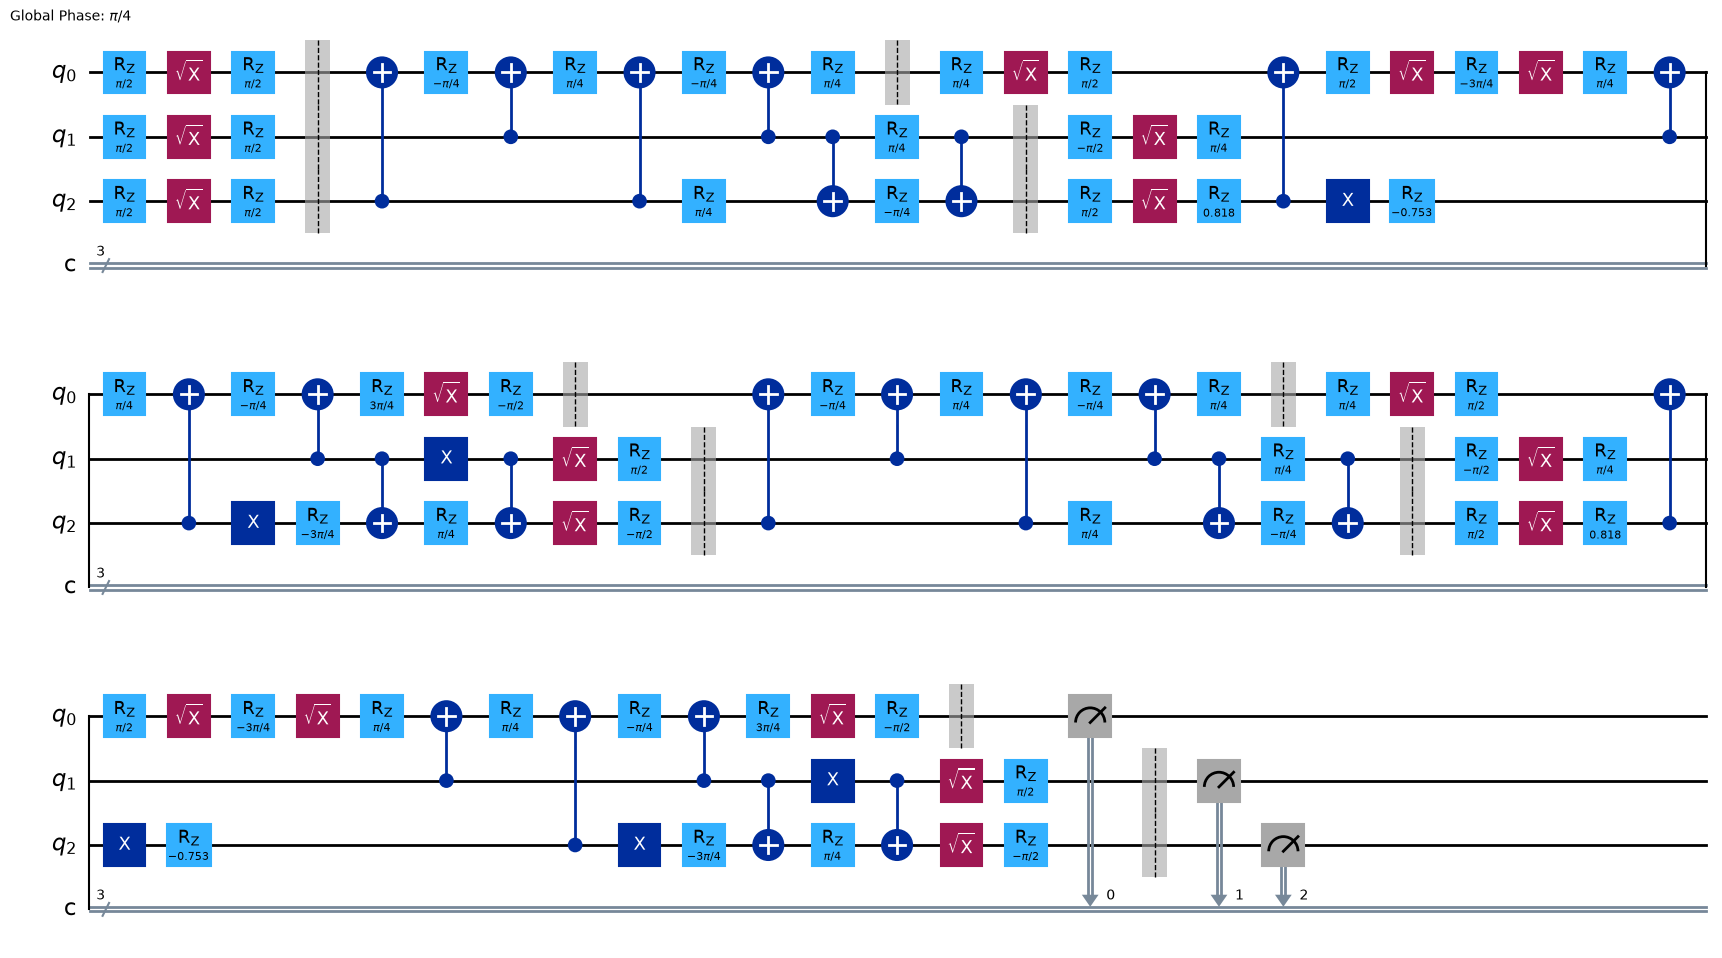

In [15]:
from qiskit import transpile

# Define hardware basis gates
basis_gates = ['cx', 'id', 'rz', 'sx', 'x']

# Transpile circuit to basis gates
transpiled_qc = transpile(circuit, basis_gates=basis_gates, optimization_level=3)

# Display CNOT overhead and circuit depth
cnot_count = transpiled_qc.count_ops().get('cx', 0)
depth = transpiled_qc.depth()

print(f"CNOT Count: {cnot_count}")
print(f"Circuit Depth: {depth}")

transpiled_qc.draw('mpl')

In [16]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

# Initialize the Noisy Hardware Simulator
fake_backend = FakeManilaV2()
noisy_sim = AerSimulator.from_backend(fake_backend)
shots = 1024

In [17]:


# Transpile for hardware execution
trans_std = transpile(circuit, noisy_sim, optimization_level=3)

# Execute and get counts
job_std = noisy_sim.run(trans_std, shots=shots)
counts_std = job_std.result().get_counts()

print("=== 1. BASELINE STANDARD ===")
print("Measurement Counts:", counts_std)
print(f"Target '111' Probability: {counts_std.get('111', 0) / shots:.3f}\n")

=== 1. BASELINE STANDARD ===
Measurement Counts: {'111': 617, '101': 70, '000': 50, '011': 63, '001': 47, '110': 102, '100': 42, '010': 33}
Target '111' Probability: 0.603

